# Las pruebas de validación de riesgo operacional

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 03, 04 y 05 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- listar las cinco pruebas de riesgo operacional del motor, qué mide cada una y las filas versionadas del caso para ellas;
- explicar por qué estas pruebas son descriptivas: no tienen valor p, y sus luces comparan una métrica con umbrales que fija Contraste y que no son regulación;
- recalcular `oprisk.benchmark_reproduction`, `oprisk.threshold_stability`, `oprisk.capital_stability`, `oprisk.sma_ilm_response` y `oprisk.scenario_influence` con el motor y compararlas con las filas versionadas;
- ver cómo un umbral cambia una luz sin cambiar la métrica, y cómo el número de años simulados cambia una luz.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. El generador del caso C17 y sus estimadores viven en `data-pipeline/pipeline/cases/c17/`, que no es un paquete instalado: este cuaderno carga esos módulos por su ruta (importar todo el paquete `pipeline` importaría todos los casos y sus dependencias pesadas). La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import aggregate, distributions
from riskvalidation.validation import oprisk as oprisk_tests

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Las variantes del caso C17 versionan 31 filas de pruebas cada una (27 la variante con índice de cola 1,1): una reproducción de la vara, 24 filas de estabilidad del capital (6 peldaños de la escalera de estimación por 4 celdas de largo de historia y umbral de recolección), 4 filas de estabilidad del umbral, una respuesta del enfoque estándar a una pérdida grande y una influencia de escenarios. La variante con índice de cola 1,1 tiene 20 filas de estabilidad del capital, cuatro menos, porque la aproximación con corrección de media no existe ahí (cuaderno 04).

- **Archivos que se leen:** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json` y `xi-1-1.json`, la clave `tests`, más `outputs.cells`, `outputs.truth`, `outputs.sma_response` y `outputs.scenario_influence` para recalcularlas.
- **Historias:** donde una prueba necesita historias, el cuaderno las regenera desde las semillas versionadas con el generador del caso, cargado por su ruta como en el cuaderno 02, y corre el estimador propio del caso `replicate.estimate`, que compone funciones del motor.

La celda siguiente carga los cuatro documentos y el generador.

In [2]:
# Cargar los cuatro documentos de las variantes y el generador y el estimador del caso por ruta
ROOT = Path("../../..").resolve()
docs = {name: json.loads((ROOT / "data" / "derived" / "C17" / (name + ".json")).read_text(encoding="utf-8")) for name in ("xi-0-6", "xi-0-8", "xi-0-96", "xi-1-1")}
sys.dont_write_bytecode = True
shell = types.ModuleType("c17")
shell.__path__ = [str(ROOT / "data-pipeline" / "pipeline" / "cases" / "c17")]
sys.modules["c17"] = shell
from c17 import generator, params as case_params, replicate

for name, doc in docs.items():
    print(name, "| pruebas versionadas:", len(doc["tests"]), "| calculado por riskvalidation", doc["provenance"]["riskvalidation_version"])

xi-0-6 | pruebas versionadas: 31 | calculado por riskvalidation 0.7.0
xi-0-8 | pruebas versionadas: 31 | calculado por riskvalidation 0.7.0
xi-0-96 | pruebas versionadas: 31 | calculado por riskvalidation 0.7.0
xi-1-1 | pruebas versionadas: 27 | calculado por riskvalidation 0.7.0


## Método

### Paso 1: las cinco pruebas y qué guarda una fila

Cada prueba devuelve un `TestResult`. En la familia de riesgo operacional los campos `p_value`, `alpha_amber` y `alpha_red` están vacíos por diseño: las pruebas son **descriptivas**. Una métrica se compara con dos umbrales que viajan en la fila, en `policy_version` y en `extras["thresholds"]`, para que un lector vea por qué una luz tiene su color. Los umbrales son elecciones internas de Contraste para este caso, no umbrales regulatorios.

| Prueba | Métrica | Qué pregunta |
|---|---|---|
| `oprisk.benchmark_reproduction` | la mayor desviación sobre su tolerancia | ¿el motor reproduce la vara de Shevchenko? |
| `oprisk.threshold_stability` | rango del índice de cola ajustado entre umbrales | ¿el índice de cola deriva con el umbral? |
| `oprisk.capital_stability` | (p75 - p25) / verdad, y el sesgo mediana / verdad - 1 | ¿el capital es estable entre historias y sin sesgo frente a la verdad? |
| `oprisk.sma_ilm_response` | ILM después menos ILM antes de una pérdida agregada | ¿el multiplicador del SMA salta con una pérdida grande? |
| `oprisk.scenario_influence` | mayor influencia absoluta de un escenario | ¿un escenario mueve demasiado el capital? |

La celda siguiente cuenta las filas versionadas de cada prueba por luz para cada variante y verifica que ninguna tiene valor p.

In [3]:
# Contar las filas versionadas de cada prueba por luz, y verificar que ninguna fila lleva un valor p
for name, doc in docs.items():
    counts = {}
    for row in doc["tests"]:
        counts.setdefault(row["test_id"], {}).setdefault(row["light"], 0)
        counts[row["test_id"]][row["light"]] += 1
    print(name, "| filas con valor p:", sum(row["p_value"] is not None for row in doc["tests"]))
    for test_id, by_light in counts.items():
        print("   %-32s %s" % (test_id, by_light))

xi-0-6 | filas con valor p: 0
   oprisk.benchmark_reproduction    {'green': 1}
   oprisk.capital_stability         {'red': 24}
   oprisk.threshold_stability       {'green': 4}
   oprisk.sma_ilm_response          {'red': 1}
   oprisk.scenario_influence        {'amber': 1}
xi-0-8 | filas con valor p: 0
   oprisk.benchmark_reproduction    {'green': 1}
   oprisk.capital_stability         {'red': 24}
   oprisk.threshold_stability       {'green': 4}
   oprisk.sma_ilm_response          {'red': 1}
   oprisk.scenario_influence        {'green': 1}
xi-0-96 | filas con valor p: 0
   oprisk.benchmark_reproduction    {'green': 1}
   oprisk.capital_stability         {'red': 24}
   oprisk.threshold_stability       {'green': 4}
   oprisk.sma_ilm_response          {'red': 1}
   oprisk.scenario_influence        {'green': 1}
xi-1-1 | filas con valor p: 0
   oprisk.benchmark_reproduction    {'green': 1}
   oprisk.capital_stability         {'red': 20}
   oprisk.threshold_stability       {'green': 4}
   opri

### Paso 2: la vara, y por qué su luz depende de los años

La prueba de reproducción del cuaderno 03 es verde en los cuatro documentos. Su cuantil Monte Carlo es el componente débil: el error estándar cae como la raíz cuadrada del número de años, así que la misma prueba con menos años simulados puede ponerse roja. La celda siguiente recalcula la prueba con los cuantiles de Panjer y de Fourier del cuaderno 03 y un Monte Carlo de solo 200.000 años en lugar del 1.000.000 de la fila versionada.

In [4]:
# La prueba de referencia con un Monte Carlo de 200.000 años en lugar de 1.000.000
moments = aggregate.compound_poisson_moments(100.0, "lognormal", (0.0, 2.0))
severity_masses = aggregate.discretise_severity("lognormal", (0.0, 2.0), 1.0, 6000)
q_panjer = aggregate.quantile_from_pmf(aggregate.panjer_recursion("poisson", (100.0,), severity_masses), 1.0, 0.999)
q_fft = aggregate.quantile_from_pmf(aggregate.fft_aggregate("poisson", (100.0,), severity_masses), 1.0, 0.999)
short_run = aggregate.simulate_annual_losses("poisson", (100.0,), "lognormal", (0.0, 2.0), 200_000, 2010)
q_mc, se_mc = aggregate.mc_quantile(short_run.losses, 0.999)
bench = oprisk_tests.benchmark_reproduction((moments.mean, moments.variance, moments.skewness), {"monte-carlo": q_mc, "panjer": q_panjer, "fft": q_fft}, moment_rel_tol=1e-5)
committed_bench = next(row for row in docs["xi-0-8"]["tests"] if row["test_id"] == "oprisk.benchmark_reproduction")
print("Monte Carlo, 200000 años: q = %.1f (error estándar %.1f) | cuantil continuo publicado 5853.1" % (q_mc, se_mc))
print("recalculada: metric %.3f, luz %s | versionada (1000000 de años): metric %.3f, luz %s" % (bench.metric, bench.light.value, committed_bench["metric"], committed_bench["light"]))

Monte Carlo, 200000 años: q = 6290.7 (error estándar 263.7) | cuantil continuo publicado 5853.1
recalculada: metric 7.476, luz red | versionada (1000000 de años): metric 0.197, luz green


### Paso 3: estabilidad del umbral, una prueba sobre el perfil mediano

Las filas versionadas de `oprisk.threshold_stability` pertenecen al peldaño de empalme de cada celda y juzgan el perfil **mediano** del índice de cola sobre las 1.000 historias, con umbrales 1, 2, 4 y 8 veces el umbral de recolección. Su métrica es el rango de esas cuatro medianas. La celda siguiente lee las medianas de la celda con 10 años y umbral de EUR 20.000, corre la prueba del motor sobre ellas y la compara con la fila versionada; luego pone al lado el rango de la historia única del cuaderno 02.

In [5]:
# La prueba de estabilidad del umbral sobre el perfil mediano versionado, y sobre la historia única del cuaderno 02
cell = next(c for c in docs["xi-0-8"]["outputs"]["cells"] if c["id"] == "y10-h20000")
thresholds = np.array([row["threshold_eur"] for row in cell["threshold_stability"]])
medians = np.array([row["tail_index"]["median"] for row in cell["threshold_stability"]])
median_test = oprisk_tests.threshold_stability(thresholds, medians, model_id="lda-splice")
committed_row = next(r for r in docs["xi-0-8"]["tests"] if r["test_id"] == "oprisk.threshold_stability" and r["segment"] == "y10-h20000")
print("perfil mediano:", np.round(medians, 4), "| rango %.5f, luz %s | versionada %.5f, %s" % (median_test.metric, median_test.light.value, committed_row["metric"], committed_row["light"]))
variant = generator.variant(0.8)
one = generator.draw_history(variant, 4208002, 10).recorded(20_000.0)
profile = distributions.tail_index_profile(one.amounts, thresholds)
single = oprisk_tests.threshold_stability(profile.thresholds, np.where(profile.converged, profile.xi, np.nan), model_id="lda-splice")
print("historia única (semilla 4208002): xi = %s | rango %.4f, luz %s" % (np.round(profile.xi, 3), single.metric, single.light.value))

perfil mediano: [0.799  0.7924 0.7864 0.7796] | rango 0.01941, luz green | versionada 0.01941, green
historia única (semilla 4208002): xi = [0.803 0.914 0.882 0.874] | rango 0.1104, luz amber


### Paso 4: estabilidad del capital, la prueba alrededor de la cual se construye el caso

La prueba toma el capital de 99,9% de un peldaño sobre muchas historias independientes y el cuantil verdadero. Su métrica es la dispersión $(p_{75} - p_{25}) / \text{verdad}$ y su estadístico el sesgo $\text{mediana}/\text{verdad} - 1$; la luz es la peor de las dos frente a umbrales de 0,25 y 0,50 para la dispersión y 0,10 y 0,25 para el sesgo absoluto. Las filas versionadas usan 1.000 historias por celda. Aquí corremos el estimador propio del caso sobre las primeras 40 historias de la celda con índice de cola 0,8, 10 años y umbral EUR 20.000, cuyas semillas son las de la celda versionada (unos 15 segundos), calculamos la prueba para cuatro peldaños e imprimimos la fila versionada al lado.

In [6]:
# Estimar 40 historias independientes con el estimador del caso y correr la prueba de estabilidad del capital en cuatro peldaños
first_seed, n_histories = generator.cell_seeds(42, 1, 3, 40)
bi = docs["xi-0-8"]["outputs"]["bank"]["business_indicator"]["bi_eur"]
runs = [replicate.estimate(variant, first_seed + k, 10, 20_000.0, bi, None, 20_000) for k in range(n_histories)]
true_quantile = docs["xi-0-8"]["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
rows = {}
print("%-26s %5s %10s %8s %8s | %s" % ("peldaño", "n", "dispersión", "sesgo", "luz", "versionada sobre 1000: dispersión, sesgo, luz"))
for rung in ("lda_lognormal", "lda_lognormal_truncated", "lda_splice", "sla"):
    capitals = np.array([r[rung] for r in runs])
    capitals = capitals[np.isfinite(capitals)]
    result = oprisk_tests.capital_stability(capitals, true_quantile, model_id=rung)
    committed = next(t for t in docs["xi-0-8"]["tests"] if t["test_id"] == "oprisk.capital_stability" and t["segment"] == "y10-h20000" and t["model_id"] == rung.replace("_", "-"))
    rows[rung] = result
    print("%-26s %5d %10.3f %+8.3f %8s | %.3f %+.3f %s" % (rung, capitals.size, result.metric, result.statistic, result.light.value, committed["metric"], committed["statistic"], committed["light"]))

peldaño                        n dispersión    sesgo      luz | versionada sobre 1000: dispersión, sesgo, luz
lda_lognormal                 40      0.007   -0.957      red | 0.008 -0.958 red
lda_lognormal_truncated       37      0.322   -0.685      red | 0.275 -0.738 red
lda_splice                    28      2.347   +0.511      red | 1.983 -0.091 red
sla                           40      1.234   +0.199      red | 1.020 -0.037 red


### Paso 5: los umbrales son una elección

La métrica no cambia cuando cambia un umbral; la luz sí. La celda siguiente corre de nuevo la misma prueba sobre los capitales del empalme con umbrales diez veces más anchos en la dispersión y el sesgo (verde en 2,5 y 1,0, ámbar en 5,0 y 2,5) e imprime cómo se mueve la luz. Es la razón por la que un lector de una fila debe leer sus umbrales: un verde con umbrales tan anchos dice casi nada.

In [7]:
# Los mismos capitales con umbrales diez veces más anchos: la métrica se mantiene, la luz cambia
splice_capitals = np.array([r["lda_splice"] for r in runs])
splice_capitals = splice_capitals[np.isfinite(splice_capitals)]
wide = oprisk_tests.capital_stability(splice_capitals, true_quantile, model_id="lda_splice", dispersion_green=2.5, dispersion_amber=5.0, bias_green=1.0, bias_amber=2.5)
print("umbrales del caso: %s -> métrica %.3f, luz %s" % (rows["lda_splice"].extras["thresholds"], rows["lda_splice"].metric, rows["lda_splice"].light.value))
print("umbrales diez veces más anchos: %s -> métrica %.3f, luz %s" % (wide.extras["thresholds"], wide.metric, wide.light.value))

umbrales del caso: {'dispersion_green': 0.25, 'dispersion_amber': 0.5, 'bias_green': 0.1, 'bias_amber': 0.25} -> métrica 2.347, luz red
umbrales diez veces más anchos: {'dispersion_green': 2.5, 'dispersion_amber': 5.0, 'bias_green': 1.0, 'bias_amber': 2.5} -> métrica 2.347, luz green


### Paso 6: la respuesta del SMA y la influencia de los escenarios, en las cuatro variantes

Las dos últimas pruebas se aplican a una sola historia y a un solo conjunto de escenarios por variante. La celda siguiente regenera, para cada variante, la historia detrás del bloque `sma_response` versionado y corre `oprisk.sma_ilm_response` con una pérdida de la mitad del componente agregada; luego corre `oprisk.scenario_influence` sobre las influencias versionadas. Ambas se comparan con las filas versionadas.

In [8]:
# Correr las pruebas de respuesta del SMA y de influencia de escenarios en las cuatro variantes
print("%-8s %-24s %10s %8s | %10s %8s" % ("", "", "recalculada", "", "versionada", ""))
for name, doc in docs.items():
    block = doc["outputs"]["sma_response"]
    history = generator.draw_history(generator.variant(doc["outputs"]["tail_index"]), block["seed"], 10).recorded(20_000.0)
    response_test = oprisk_tests.sma_ilm_response(block["bic_eur"], history.annual, 0.5 * block["bic_eur"], model_id="sma")
    committed_response = next(t for t in doc["tests"] if t["test_id"] == "oprisk.sma_ilm_response")
    influences = np.array([s["influence"] for s in doc["outputs"]["scenario_influence"]["scenarios"]])
    influence_test = oprisk_tests.scenario_influence(influences, model_id="scenario")
    committed_influence = next(t for t in doc["tests"] if t["test_id"] == "oprisk.scenario_influence")
    print("%-8s %-24s %10.4f %8s | %10.4f %8s" % (name, "sma_ilm_response", response_test.metric, response_test.light.value, committed_response["metric"], committed_response["light"]))
    print("%-8s %-24s %10.4f %8s | %10.4f %8s" % (name, "scenario_influence", influence_test.metric, influence_test.light.value, committed_influence["metric"], committed_influence["light"]))

                                  recalculada          | versionada         
xi-0-6   sma_ilm_response             0.2753      red |     0.2753      red
xi-0-6   scenario_influence           0.1652    amber |     0.1652    amber
xi-0-8   sma_ilm_response             0.2520      red |     0.2520      red
xi-0-8   scenario_influence           0.0828    green |     0.0828    green
xi-0-96  sma_ilm_response             0.2314      red |     0.2314      red
xi-0-96  scenario_influence           0.0926    green |     0.0926    green
xi-1-1   sma_ilm_response             0.2518      red |     0.2518      red
xi-1-1   scenario_influence           0.1481    amber |     0.1481    amber


La última celda muestra de una vez todas las filas versionadas de estabilidad del capital. Cada punto es un peldaño en una celda de una variante: su dispersión en el eje horizontal (logarítmico) y el sesgo absoluto en el vertical, con los umbrales del caso dibujados como líneas. Casi todos los puntos caen en la zona roja, por razones distintas: el peldaño lognormal tiene una dispersión minúscula y un sesgo cercano a -1 (es estable y equivocado), los peldaños de empalme y de aproximación tienen una dispersión de orden 1 o más y una mediana mucho más cercana a la verdad (entre 0,6 y 1,0 veces ella): más cercanos en promedio, e inestables.

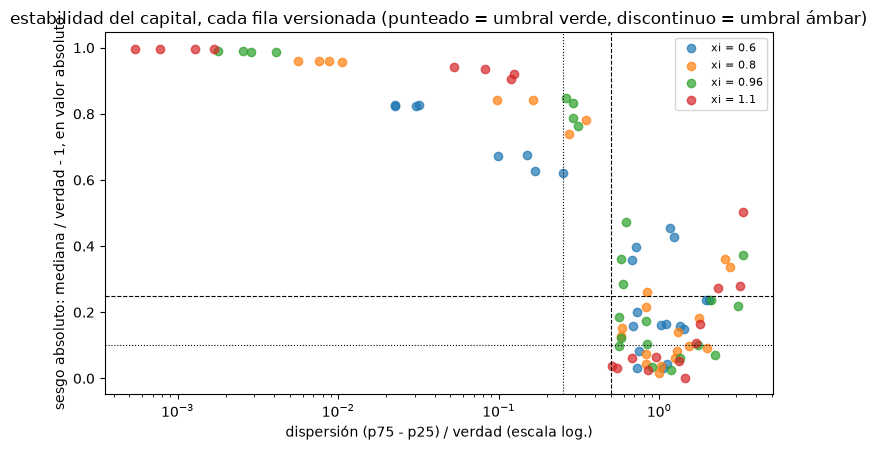

In [9]:
# Draw dispersion against absolute bias for every committed capital-stability row
fig, ax = plt.subplots(figsize=(7.5, 4.6))
colors = {"xi-0-6": "tab:blue", "xi-0-8": "tab:orange", "xi-0-96": "tab:green", "xi-1-1": "tab:red"}
for name, doc in docs.items():
    rows_c = [t for t in doc["tests"] if t["test_id"] == "oprisk.capital_stability"]
    ax.scatter([t["metric"] for t in rows_c], [abs(t["statistic"]) for t in rows_c], color=colors[name], alpha=0.7, label="xi = " + str(doc["outputs"]["tail_index"]))
for gate, style in ((0.25, ":"), (0.50, "--")):
    ax.axvline(gate, color="black", linestyle=style, linewidth=0.8)
for gate, style in ((0.10, ":"), (0.25, "--")):
    ax.axhline(gate, color="black", linestyle=style, linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel("dispersión (p75 - p25) / verdad (escala log.)")
ax.set_ylabel("sesgo absoluto: mediana / verdad - 1, en valor absoluto")
ax.set_title("estabilidad del capital, cada fila versionada (punteado = umbral verde, discontinuo = umbral ámbar)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **Sin valores p.** Las 120 filas versionadas de las cuatro variantes (31, 31, 31 y 27) tienen el valor p vacío: las luces comparan una métrica con umbrales que fija el caso.
- **La vara y los años.** La prueba de reproducción con un Monte Carlo de 200.000 años da un cuantil de 6.290,7 con un error estándar de 263,7, una métrica de 7,476 y una luz roja, donde la fila versionada, con 1.000.000 de años, tiene 0,197 y es verde. La prueba juzga la simulación tanto como al motor.
- **Estabilidad del umbral.** La prueba corrida sobre el perfil mediano versionado (0,799, 0,792, 0,786, 0,780) tiene un rango de 0,0194 y es verde, igual a la fila versionada; sobre la historia única del cuaderno 02 el rango es 0,1104 y la luz es ámbar. Una fila verde de esta prueba dice que el perfil **mediano** es plano, no que lo sea la única historia de un banco.
- **Estabilidad del capital.** Con 40 historias, la lognormal que ignora el umbral tiene una dispersión de 0,007 y un sesgo de -0,957, estable y 96% demasiado baja, siendo la fila versionada sobre 1.000 historias 0,008 y -0,958. La lognormal truncada (0,322, -0,685), el empalme (2,347, +0,511 en las 28 historias donde está definido) y la aproximación (1,234, +0,199) son rojos, frente a 0,275, 1,983 y 1,020 sobre 1.000 historias. Con 40 historias el sesgo de los peldaños inestables es a su vez inestable: el empalme muestra +0,511 donde la mediana versionada es -0,091.
- **Los umbrales son una elección.** Los mismos capitales del empalme con umbrales diez veces más anchos tienen la misma métrica, 2,347, y una luz verde. Cada luz hay que leerla con sus umbrales, que viajan en la fila.
- **Las otras dos pruebas.** La respuesta del SMA es roja en las cuatro variantes (métricas 0,275, 0,252, 0,231 y 0,252 sobre el umbral ámbar de 0,15) y la influencia de escenarios es ámbar con índices de cola 0,6 y 1,1 (0,165 y 0,148) y verde con 0,8 y 0,96 (0,083 y 0,093); el recálculo es igual a las filas versionadas con cuatro decimales en las cuatro variantes.
- **La tabla completa.** En la figura, 92 de las 92 filas versionadas de estabilidad del capital (24, 24, 24 y 20) son rojas: el peldaño lognormal por sesgado, los demás por dispersos.
- **Qué motor.** Las filas versionadas las calculó riskvalidation 0.7.0 y los recálculos de aquí, con la 0.8.1, son iguales a ellas donde usan los mismos insumos.

Lo que este cuaderno no muestra: qué significa la dispersión para la elección entre el LDA y el SMA (cuaderno 07), ni cómo depende la dispersión del largo de la historia y del índice de cola (el cuaderno de nivel 4).

## Resumen

- Las cinco pruebas de riesgo operacional son descriptivas: una métrica frente a umbrales que fija Contraste, sin valor p, y los umbrales viajan en cada fila.
- La misma métrica da luces distintas con umbrales distintos, y la prueba de la vara se pone roja cuando su Monte Carlo tiene pocos años.
- La fila de estabilidad del umbral juzga el perfil mediano; una historia puede derivar mucho más.
- En la grilla versionada toda fila de estabilidad del capital es roja, unas porque el peldaño tiene sesgo y otras porque es disperso.

**Qué probar a continuación.** Cambia el número de historias del paso 4 de 40 a 100 (unos 45 segundos) y mira cómo el sesgo del empalme se asienta hacia el valor versionado. Cambia los umbrales de `threshold_stability` a 0,25 y 0,5 y mira la historia única ponerse verde. Sigue con el cuaderno 07.

## Referencias

- BCBS, Basel Framework OPE25, Calculation of RWA for operational risk. https://www.bis.org/basel_framework/chapter/OPE/25.htm
- Chavez-Demoulin, V., Embrechts, P. y Neslehova, J. (2006), Quantitative models for operational risk: extremes, dependence and aggregation, Journal of Banking and Finance 30(10), 2635-2658. https://doi.org/10.1016/j.jbankfin.2005.11.008
- Shevchenko, P. V. (2010), Calculation of aggregate loss distributions, Journal of Operational Risk 5(2), 3-40. https://arxiv.org/abs/1008.1108 y https://doi.org/10.21314/JOP.2010.077
- Shevchenko, P. V. y Wuthrich, M. V. (2006), The structural modeling of operational risk via Bayesian inference, Journal of Operational Risk 1(3), 3-26. https://doi.org/10.21314/JOP.2006.016